# Sprint 4 Project: E-Commerce Customer Behavior EDA

Welcome to your Sprint 4 final project. In this project, you will apply everything you've learned across Sprints 1–4 to perform a complete Exploratory Data Analysis on the **Olist Brazilian E-Commerce dataset** — real data from a real e-commerce platform.


## Dataset

You'll work with 7 CSV files from the Olist e-commerce dataset:

| File | Rows | Description |
|---|---|---|
| `olist_orders_dataset.csv` | 99,441 | Orders with timestamps and status |
| `olist_order_items_dataset.csv` | 112,650 | Items per order with price and freight |
| `olist_customers_dataset.csv` | 99,441 | Customer ID, city, state |
| `olist_products_dataset.csv` | 32,951 | Products with category and dimensions |
| `olist_order_reviews_dataset.csv` | 99,224 | Review scores (1–5 stars) |
| `olist_order_payments_dataset.csv` | 103,886 | Payment type and value |
| `product_category_name_translation.csv` | 71 | Portuguese → English category names |

Let's get started!

---

## Setup

Run the cells below to import the libraries you'll need and load the datasets. The data is hosted on GitHub, so you can load it with one line of code per file — no uploads required.

In [1]:
# Import libraries
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

# Make charts look clean and consistent throughout the notebook
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

# Confirm versions
print(f"pandas version: {pd.__version__}")
print("Setup complete!")


/home/hatch/workspace/consult50/projects/eda/.venv/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


pandas version: 2.1.4
Setup complete!


In [2]:
# Load the 7 datasets from the curriculum GitHub repo
BASE_URL = 'https://practicum-content.s3.us-west-1.amazonaws.com/data-analytics/eda-project/'

orders = pd.read_csv(BASE_URL + 'olist_orders_dataset.csv')
items = pd.read_csv(BASE_URL + 'olist_order_items_dataset.csv')
customers = pd.read_csv(BASE_URL + 'olist_customers_dataset.csv')
products = pd.read_csv(BASE_URL + 'olist_products_dataset.csv')
reviews = pd.read_csv(BASE_URL + 'olist_order_reviews_dataset.csv')
payments = pd.read_csv(BASE_URL + 'olist_order_payments_dataset.csv')
translation = pd.read_csv(BASE_URL + 'product_category_name_translation.csv')

print(f"orders:      {orders.shape}")
print(f"items:       {items.shape}")
print(f"customers:   {customers.shape}")
print(f"products:    {products.shape}")
print(f"reviews:     {reviews.shape}")
print(f"payments:    {payments.shape}")
print(f"translation: {translation.shape}")

orders:      (99441, 8)
items:       (112650, 7)
customers:   (99441, 5)
products:    (32951, 9)
reviews:     (99224, 7)
payments:    (103886, 5)
translation: (71, 2)


In [3]:
# Set up an in-memory SQLite database with all 7 tables
# This lets you run SQL queries directly against the DataFrames
conn = sqlite3.connect(':memory:')

orders.to_sql('orders', conn, index=False, if_exists='replace')
items.to_sql('items', conn, index=False, if_exists='replace')
customers.to_sql('customers', conn, index=False, if_exists='replace')
products.to_sql('products', conn, index=False, if_exists='replace')
reviews.to_sql('reviews', conn, index=False, if_exists='replace')
payments.to_sql('payments', conn, index=False, if_exists='replace')
translation.to_sql('translation', conn, index=False, if_exists='replace')

print("SQLite database ready. You can now run SQL queries with pd.read_sql().")

SQLite database ready. You can now run SQL queries with pd.read_sql().


---

## Data Quality Check (before answering the questions)

Before trusting any result, an analyst checks two things in **every** table: *missing values* and *duplicate rows*. The next cell audits all 7 tables at once so the cleaning decisions that follow are based on evidence, not guesses.

In [4]:
# Count missing values and exact duplicate rows in every table.
# .isnull().sum() adds up the empty cells column by column; summing that
# Series gives one total per table. .duplicated().sum() counts rows that
# are complete copies of an earlier row.
tables = {
    'orders': orders, 'items': items, 'customers': customers,
    'products': products, 'reviews': reviews, 'payments': payments,
    'translation': translation,
}

audit_rows = []
for name, df in tables.items():
    audit_rows.append({
        'table': name,
        'rows': len(df),
        'columns': len(df.columns),
        'missing_cells_total': int(df.isnull().sum().sum()),
        'exact_duplicate_rows': int(df.duplicated().sum()),
    })

audit = pd.DataFrame(audit_rows)
print(audit.to_string(index=False))


      table   rows  columns  missing_cells_total  exact_duplicate_rows
     orders  99441        8                 4908                     0
      items 112650        7                    0                     0
  customers  99441        5                    0                     0
   products  32951        9                 2448                     0
    reviews  99224        7               145903                     0
   payments 103886        5                    0                     0
translation     71        2                    0                     0


### Cleaning decisions (what I changed, and what I deliberately left alone)

**Duplicates — nothing to drop.** No table contains a single exact duplicate row, and the key IDs are unique where they must be (`order_id` in orders, `customer_id`, `product_id`). One subtlety: 814 `review_id` values repeat in `reviews`, but those rows differ in their other columns, so they are separate review records, not copies. Dropping them would delete real customer feedback, so **all rows are kept**.

**Missing values — kept, because they carry meaning:**
- In `orders`, `order_approved_at` (160 missing), `order_delivered_carrier_date` (1,783) and `order_delivered_customer_date` (2,965) are empty precisely because those orders have not reached that stage yet (they were still processing, shipped, canceled, etc.). Filling them with invented dates would corrupt every delivery calculation, so they stay empty and analyses that need a delivery date filter to delivered orders only (see Q9).
- In `products`, 610 products have no category/name/description data. The products still exist and still sell, so the rows stay; they simply have no English category after the merge in Q5 (623 products in total, once a handful of Portuguese categories with no translation are included).
- In `reviews`, most rows have no comment title (87,656) or message (58,247) — most customers rate with stars only. The scores are complete, which is all this project uses.

**Type fix (done in Q2):** all five timestamp columns in `orders` arrive as text and are converted to real datetimes so date arithmetic and monthly grouping work.

---

## Question 1: Inspect the orders DataFrame

**Your task:** For the `orders` DataFrame:
1. Print its shape
2. Print the first 5 rows with `.head()`
3. Print column info with `.info()`

This is the very first thing every analyst does with a new dataset.

*Skills: Sprint 4 Ch 01 (Pandas inspection)*

In [5]:
# Question 1: Inspect the orders DataFrame

# 1) Shape: (rows, columns)
print("Shape of orders (rows, columns):", orders.shape)

# 2) First 5 rows
print("\nFirst 5 rows:")
orders.head()


Shape of orders (rows, columns): (99441, 8)

First 5 rows:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [6]:
# .info() shows each column's name, how many values are present,
# and the data type — our first hint that the timestamps are still text.
orders.info()

# Descriptive statistics for the numeric tables we lean on most.
# Reading guide: 'count' = values present, 'mean' = average,
# 50% = the median. When the mean is far above the median (as with
# item price below), a minority of large values is pulling it up.
print("\nItems — price and freight:")
print(items[['price', 'freight_value']].describe().round(2))

print("\nPayments — payment value:")
print(payments[['payment_value']].describe().round(2))

print("\nReviews — score distribution (share of all reviews):")
print((reviews['review_score'].value_counts(normalize=True).sort_index() * 100).round(1))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

Items — price and freight:
           price  freight_value
count  112650.00      112650.00
mean      120.65          19.99
std       183.63          15.81
min         0.85           0.00
25%        39.90          13.08
50%        74.99          16.26
75%       

**What this shows:** `orders` holds 99,441 orders across 8 columns (Sep 2016 – Oct 2018, confirmed in Q8). The first pattern worth remembering: item prices are **right-skewed** — the average item costs R$120.65 but the median is only R$74.99, so a minority of expensive items pulls the average up. Reviews average about 4.1 stars, and 57.8% of all reviews are 5 stars — a generally happy customer base with a dissatisfied tail (11.5% gave 1 star) that Q9 will explain.

---

## Question 2: Clean the orders data

The `orders` DataFrame has timestamp columns stored as strings, and a few have missing values.

**Your task:**
1. Use `.isnull().sum()` to count missing values in each column of `orders`
2. Convert `order_purchase_timestamp` and `order_delivered_customer_date` to datetime using `pd.to_datetime()`
3. Print the dtypes after conversion to verify

*Skills: Sprint 4 Ch 02 (Cleaning, dtype conversion)*

In [7]:
# Question 2: Clean the orders data

# 1) Count missing values in each column of orders
print("Missing values per column in orders:")
print(orders.isnull().sum())

# 2) Convert ALL timestamp columns from text to datetime.
# The question names the two most important ones; converting the rest
# as well keeps every date calculation in this notebook safe.
timestamp_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
]
for col in timestamp_cols:
    orders[col] = pd.to_datetime(orders[col])

# 3) Verify: the dtypes should now read datetime64[ns]
print("\nDtypes after conversion:")
print(orders.dtypes)


Missing values per column in orders:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64



Dtypes after conversion:
order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


---

## Question 3: Order status breakdown (SQL)

**Your task:** Write a SQL query against the `orders` table that returns:
- `order_status`
- `num_orders` — count of orders with that status
- `pct` — percentage of total orders, rounded to 2 decimals

Sort by `num_orders` descending. Save the result to a DataFrame called `status_summary` and print it.

**Hint:** Use `pd.read_sql("...", conn)`. The percentage trick is `COUNT(*) * 100.0 / (SELECT COUNT(*) FROM orders)`.

*Skills: Sprint 2 (SQL aggregation), Sprint 4 Ch 03 (Descriptive stats)*

In [8]:
# Question 3: Order status breakdown (SQL)

# SQL does the counting: GROUP BY collapses orders into one row per
# status, COUNT(*) counts them, and the subquery in the SELECT gives
# the percentage of the grand total.
query = """
SELECT
    order_status,
    COUNT(*) AS num_orders,
    ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM orders), 2) AS pct
FROM orders
GROUP BY order_status
ORDER BY num_orders DESC
"""

status_summary = pd.read_sql(query, conn)
print(status_summary.to_string(index=False))


order_status  num_orders   pct
   delivered       96478 97.02
     shipped        1107  1.11
    canceled         625  0.63
 unavailable         609  0.61
    invoiced         314  0.32
  processing         301  0.30
     created           5  0.01
    approved           2  0.00


**Finding:** The operation is healthy — **97.02% of orders (96,478) were delivered**. Only 625 orders (0.63%) were canceled and 609 (0.61%) marked unavailable; the rest were still in the pipeline (shipped, invoiced, processing) when the data was captured.

---

## Question 4: Top 10 highest-revenue orders (SQL JOIN)

Each order can have multiple items. Total order revenue = sum of `price + freight_value` across all its items.

**Your task:** Write a SQL query that JOINs `orders` and `items` to find the **10 highest-revenue orders**. Return:
- `order_id`
- `order_status`
- `total_revenue` — rounded to 2 decimals

Save the result to `top_orders` and print it.

*Skills: Sprint 2 (SQL JOIN, GROUP BY), Sprint 4 Ch 06 (combining tables)*

In [9]:
# Question 4: Top 10 highest-revenue orders (SQL JOIN)

# An order's revenue lives in the items table (price + freight per
# item), so JOIN brings the two tables together on order_id,
# GROUP BY rolls each order's items into one total, and LIMIT 10
# keeps only the biggest.
query = """
SELECT
    o.order_id,
    o.order_status,
    ROUND(SUM(i.price + i.freight_value), 2) AS total_revenue
FROM orders AS o
JOIN items AS i
    ON o.order_id = i.order_id
GROUP BY o.order_id, o.order_status
ORDER BY total_revenue DESC
LIMIT 10
"""

top_orders = pd.read_sql(query, conn)
print(top_orders.to_string(index=False))


                        order_id order_status  total_revenue
03caa2c082116e1d31e67e9ae3700499    delivered       13664.08
736e1922ae60d0d6a89247b851902527    delivered        7274.88
0812eb902a67711a1cb742b3cdaa65ae    delivered        6929.31
fefacc66af859508bf1a7934eab1e97f    delivered        6922.21
f5136e38d1a14a4dbd87dff67da82701    delivered        6726.66
2cc9089445046817a7539d90805e6e5a    delivered        6081.54
a96610ab360d42a2e5335a3998b4718a    delivered        4950.34
b4c4b76c642808cbe472a32b86cddc95     canceled        4809.44
199af31afc78c699f0dbf71fb178d4d4    delivered        4764.34
8dbc85d1447242f3b127dda390d56e19    delivered        4681.78


---

## Question 5: English product categories (pandas merge)

The `products` table has a Portuguese category column called `product_category_name`. The `translation` table maps each Portuguese name to its English equivalent.

**Your task:**
1. Use `products.merge(translation, on='product_category_name', how='left')` to add the English column. Save it to `products_eng`.
2. Find the **top 10 categories by number of products** using `value_counts()` on the `product_category_name_english` column. Save to `top_categories` and print it.

*Skills: Sprint 4 Ch 06 (pandas merge), Ch 03 (value_counts)*

In [10]:
# Question 5: English product categories (pandas merge)

# merge() is pandas' JOIN: match each product's Portuguese category
# to the translation table. how='left' keeps every product, even the
# ones whose category has no translation (they get an empty English name).
products_eng = products.merge(translation, on='product_category_name', how='left')

# value_counts() ranks the English categories by how many products
# each one contains; .head(10) keeps the top 10.
top_categories = products_eng['product_category_name_english'].value_counts().head(10)

print("Top 10 categories by number of products:")
print(top_categories)
print(f"\nProducts with no English category: {products_eng['product_category_name_english'].isna().sum()} of {len(products_eng)}")


Top 10 categories by number of products:
product_category_name_english
bed_bath_table           3029
sports_leisure           2867
furniture_decor          2657
health_beauty            2444
housewares               2335
auto                     1900
computers_accessories    1639
toys                     1411
watches_gifts            1329
telephony                1134
Name: count, dtype: int64

Products with no English category: 623 of 32951


---

## Question 6: Revenue and average review score by category

Now you'll combine three tables and compute multiple metrics per category.

**Your task:**
1. Build a DataFrame that merges `items` with `products_eng` (to get categories), then merges with `reviews` (to get scores). The shared key chain is: `items.product_id → products_eng.product_id` and `items.order_id → reviews.order_id`.
2. Add a `revenue` column = `price + freight_value`
3. Group by `product_category_name_english` and aggregate:
   - `total_revenue` = sum of `revenue`
   - `avg_review` = mean of `review_score`
   - `n_items` = count of `order_id`
4. Sort by `total_revenue` descending and show the **top 10 categories**. Save to `category_summary`.

*Skills: Sprint 4 Ch 06 (multi-table merge, groupby with multiple aggregations)*

In [11]:
# Question 6: Revenue and average review score by category

# Step 1 — merge the chain: items -> products_eng (adds the category)
# -> reviews (adds the score). An item links to its product by
# product_id and to its order's review by order_id.
items_cat = items.merge(products_eng, on='product_id', how='left')
items_full = items_cat.merge(reviews[['order_id', 'review_score']], on='order_id', how='left')

# Step 2 — revenue for one item = what the customer paid for the
# product plus what they paid to ship it.
items_full['revenue'] = items_full['price'] + items_full['freight_value']

# Step 3 — group by category and aggregate three metrics at once.
# Named aggregation (new_name=('column', 'function')) keeps the
# output columns readable.
category_summary = (
    items_full
    .groupby('product_category_name_english')
    .agg(
        total_revenue=('revenue', 'sum'),
        avg_review=('review_score', 'mean'),
        n_items=('order_id', 'count'),
    )
    .sort_values('total_revenue', ascending=False)
    .head(10)
    .round(2)
)

print("Top 10 categories by revenue:")
print(category_summary)


Top 10 categories by revenue:
                               total_revenue  avg_review  n_items
product_category_name_english                                    
health_beauty                     1446622.08        4.14     9727
watches_gifts                     1306761.40        4.02     6001
bed_bath_table                    1258189.51        3.90    11270
sports_leisure                    1163329.98        4.11     8700
computers_accessories             1068070.48        3.93     7894
furniture_decor                    910683.05        3.90     8415
housewares                         781170.03        4.06     6989
cool_stuff                         721492.90        4.15     3806
auto                               687374.19        4.07     4256
garden_tools                       585646.54        4.04     4361


                               total_revenue  avg_item_revenue  n_items
product_category_name_english                                          
health_beauty                     1446622.08            148.72     9727
watches_gifts                     1306761.40            217.76     6001
bed_bath_table                    1258189.51            111.64    11270
sports_leisure                    1163329.98            133.72     8700
computers_accessories             1068070.48            135.30     7894
furniture_decor                    910683.05            108.22     8415
housewares                         781170.03            111.77     6989
cool_stuff                         721492.90            189.57     3806
auto                               687374.19            161.51     4256
garden_tools                       585646.54            134.29     4361


/tmp/ipykernel_9989/363792535.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


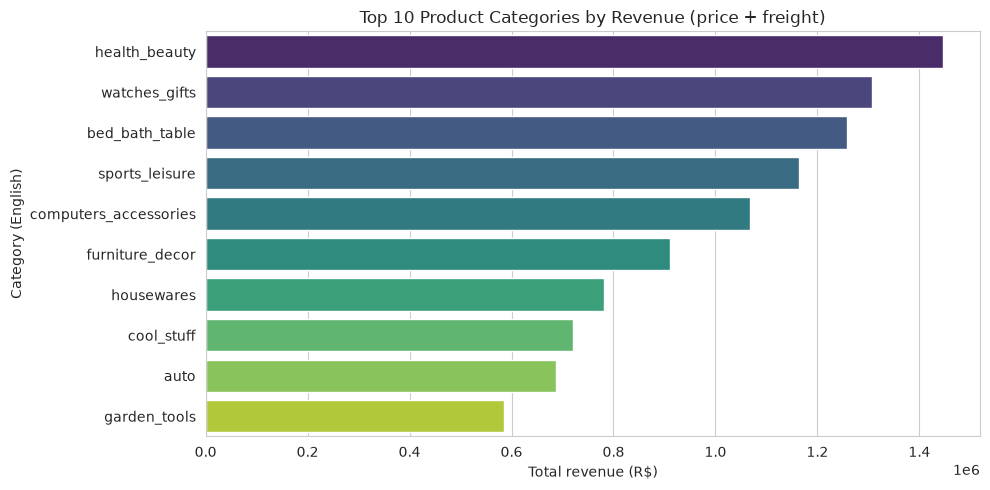

In [12]:
# Same result as a pivot_table — a second way to build the summary.
# pivot_table reshapes long data into a grid: one row per category,
# one column per aggregation. Useful when a report needs the grid shape.
category_pivot = items_full.pivot_table(
    index='product_category_name_english',
    values='revenue',
    aggfunc=['sum', 'mean', 'count'],
)
category_pivot.columns = ['total_revenue', 'avg_item_revenue', 'n_items']
print(category_pivot.sort_values('total_revenue', ascending=False).head(10).round(2))

# Bar chart of the top 10 revenue categories
plt.figure(figsize=(10, 5))
sns.barplot(
    data=category_summary.reset_index(),
    x='total_revenue', y='product_category_name_english',
    palette='viridis',
)
plt.title('Top 10 Product Categories by Revenue (price + freight)')
plt.xlabel('Total revenue (R$)')
plt.ylabel('Category (English)')
plt.tight_layout()
plt.show()


**Finding:** **Health & beauty is the money category** — R$1.45M in revenue with a strong 4.14 average review. The caution flag is **bed_bath_table**: it sells the most items (11,270) and earns R$1.26M, yet it has the joint-lowest average review in the top 10 (3.90). High volume + mediocre satisfaction is exactly where a quality problem hides.

---

## Question 7: Top 10 customer states (SQL + bar chart)

**Your task:**
1. Write a SQL query that returns the **top 10 customer states** by number of customers. Columns: `customer_state`, `num_customers`. Save to `state_top10`.
2. Create a **bar chart** of `num_customers` by `customer_state`. Add a title and rotate the x-tick labels if they overlap.

*Skills: Sprint 2 (SQL GROUP BY), Sprint 4 Ch 04 (bar chart)*

customer_state  num_customers
            SP          41746
            RJ          12852
            MG          11635
            RS           5466
            PR           5045
            SC           3637
            BA           3380
            DF           2140
            ES           2033
            GO           2020


/tmp/ipykernel_9989/813694788.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=state_top10, x='customer_state', y='num_customers', palette='Blues_r')


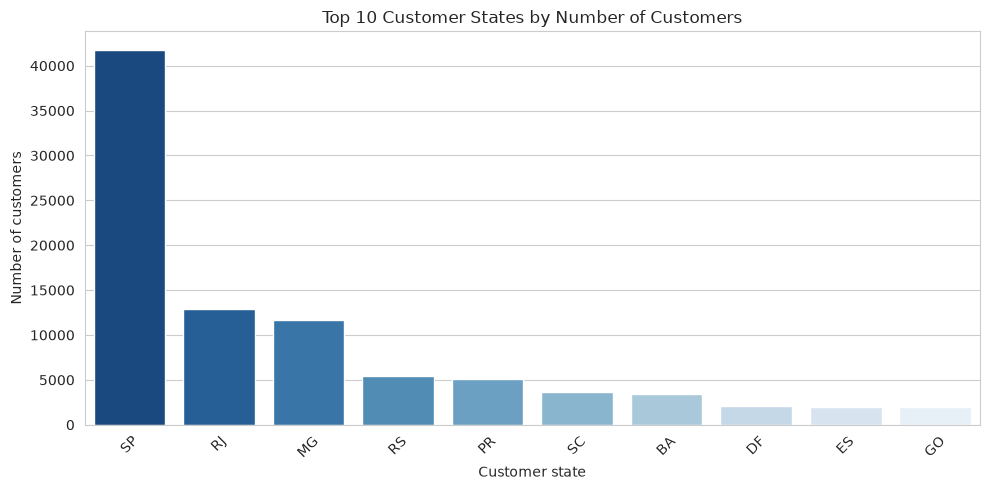

In [13]:
# Question 7: Top 10 customer states (SQL + bar chart)

# SQL counts customers per state; LIMIT 10 keeps the biggest states.
query = """
SELECT
    customer_state,
    COUNT(*) AS num_customers
FROM customers
GROUP BY customer_state
ORDER BY num_customers DESC
LIMIT 10
"""

state_top10 = pd.read_sql(query, conn)
print(state_top10.to_string(index=False))

# Bar chart of the same result
plt.figure(figsize=(10, 5))
sns.barplot(data=state_top10, x='customer_state', y='num_customers', palette='Blues_r')
plt.title('Top 10 Customer States by Number of Customers')
plt.xlabel('Customer state')
plt.ylabel('Number of customers')
plt.xticks(rotation=45)  # rotate labels so they don't overlap
plt.tight_layout()
plt.show()


In [14]:
# Completing the picture with pd.concat(): the top 10 states are not
# the whole country. Build one extra row for "All other states" and
# stack it under the top 10 — concat() glues DataFrames row-wise.
other_customers = len(customers) - state_top10['num_customers'].sum()
other_row = pd.DataFrame({'customer_state': ['OTHER'], 'num_customers': [other_customers]})

state_complete = pd.concat([state_top10, other_row], ignore_index=True)
state_complete['pct_of_customers'] = (state_complete['num_customers'] / len(customers) * 100).round(1)
print(state_complete.to_string(index=False))


customer_state  num_customers  pct_of_customers
            SP          41746              42.0
            RJ          12852              12.9
            MG          11635              11.7
            RS           5466               5.5
            PR           5045               5.1
            SC           3637               3.7
            BA           3380               3.4
            DF           2140               2.2
            ES           2033               2.0
            GO           2020               2.0
         OTHER           9487               9.5


---

## Question 8: Monthly order trend (line chart)

**Your task:**
1. From the cleaned `orders` DataFrame (with datetime columns from Q2), extract a `year_month` period from `order_purchase_timestamp` using `.dt.to_period('M')`
2. Count orders per month — save to a DataFrame called `monthly_orders` with columns `year_month` and `num_orders`
3. Plot a **line chart** of `num_orders` over time. Add a title.

**Hint:** `orders['order_purchase_timestamp'].dt.to_period('M').value_counts().sort_index()` is a fast way to get monthly counts. Convert the period index back to string for plotting.

*Skills: Sprint 4 Ch 02 (datetime), Ch 03 (groupby), Ch 04 (line chart)*

year_month  num_orders
   2016-09           4
   2016-10         324
   2016-12           1
   2017-01         800
   2017-02        1780
   2017-03        2682
   2017-04        2404
   2017-05        3700
   2017-06        3245
   2017-07        4026


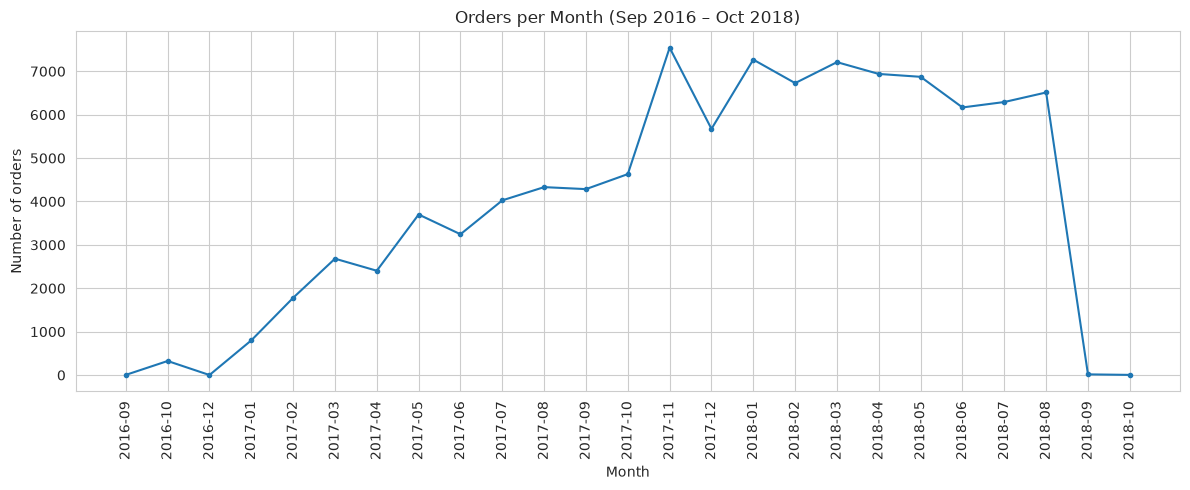


Peak month: 2017-11 with 7544 orders


In [15]:
# Question 8: Monthly order trend (line chart)

# .dt.to_period('M') turns each purchase timestamp into its month
# (e.g. 2017-11). value_counts() counts orders per month and
# sort_index() puts the months in chronological order.
monthly_counts = (
    orders['order_purchase_timestamp']
    .dt.to_period('M')
    .value_counts()
    .sort_index()
)

# Build the tidy DataFrame the question asks for. The period index is
# converted back to text ('2017-11') so it plots cleanly.
monthly_orders = monthly_counts.rename_axis('year_month').reset_index(name='num_orders')
monthly_orders['year_month'] = monthly_orders['year_month'].astype(str)
print(monthly_orders.head(10).to_string(index=False))

# Line chart of orders per month
plt.figure(figsize=(12, 5))
plt.plot(monthly_orders['year_month'], monthly_orders['num_orders'], marker='o', markersize=3)
plt.title('Orders per Month (Sep 2016 – Oct 2018)')
plt.xlabel('Month')
plt.ylabel('Number of orders')
plt.xticks(rotation=90)  # every month label, kept readable vertically
plt.tight_layout()
plt.show()

# Peak month, for the report
peak = monthly_orders.loc[monthly_orders['num_orders'].idxmax()]
print(f"\nPeak month: {peak['year_month']} with {peak['num_orders']} orders")


In [16]:
# The same monthly data as a pivot_table grid: months down the side,
# years across the top. Growth (and the November spike) is easy to
# read in this shape.
monthly_orders['year'] = monthly_orders['year_month'].str[:4]
monthly_orders['month'] = monthly_orders['year_month'].str[5:7]
monthly_pivot = monthly_orders.pivot_table(index='month', columns='year', values='num_orders')
print(monthly_pivot)


year    2016    2017    2018
month                       
01       NaN   800.0  7269.0
02       NaN  1780.0  6728.0
03       NaN  2682.0  7211.0
04       NaN  2404.0  6939.0
05       NaN  3700.0  6873.0
06       NaN  3245.0  6167.0
07       NaN  4026.0  6292.0
08       NaN  4331.0  6512.0
09       4.0  4285.0    16.0
10     324.0  4631.0     4.0
11       NaN  7544.0     NaN
12       1.0  5673.0     NaN


**Finding:** Growth is dramatic — from a few hundred orders a month in late 2016 to **6,000–7,500 a month through 2018**. The single biggest month is **November 2017 (7,544 orders)**, the Black Friday spike. Two cautions: Sep 2016 (4 orders) and Oct 2018 (4 orders) are partial edge months from when data collection started/stopped, not real demand collapses; and growth flattens during 2018 rather than continuing to climb, so the story is 'rapid growth, then a high plateau.'

---

## Question 9: Does delivery speed affect review scores?

This is a real business question: do customers who get their orders faster leave better reviews?

**Your task:**
1. From `orders`, keep only rows where `order_delivered_customer_date` is not null
2. Add a `delivery_days` column = (delivery date − purchase date) in days. **Hint:** subtract the two datetime columns and use `.dt.days`
3. Merge with `reviews` on `order_id` to get the `review_score` for each order
4. Compute the **correlation** between `delivery_days` and `review_score` using `.corr()`
5. Group by `review_score` and show the **average delivery days** for each score (1 through 5)
6. Plot a bar chart of average delivery days by review score

What pattern do you see? Add a markdown cell with your interpretation.

*Skills: Sprint 4 Ch 03 (correlation), Ch 04 (visualization), Ch 06 (merge + groupby)*

Correlation between delivery_days and review_score: -0.334
Orders analysed: 96359 (average delivery: 12.1 days)

Average delivery days by review score:
review_score
1    20.85
2    16.19
3    13.80
4    11.85
5    10.22
Name: delivery_days, dtype: float64


/tmp/ipykernel_9989/3031639251.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_days_by_score.index, y=avg_days_by_score.values, palette='RdYlGn')


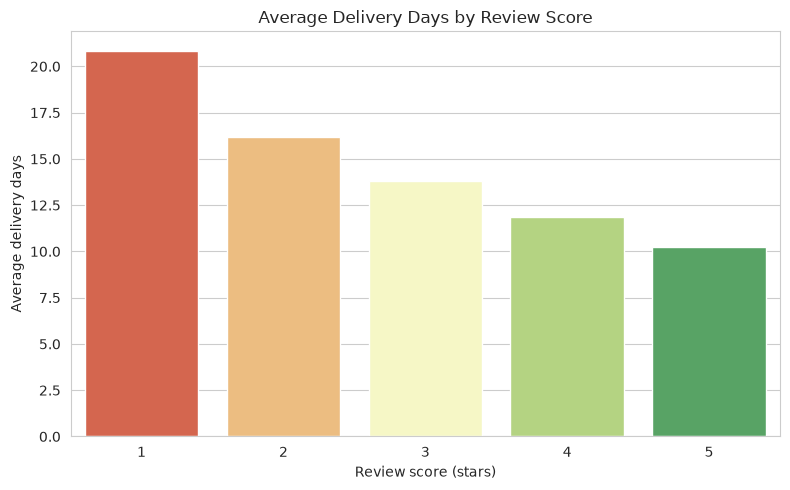

In [17]:
# Question 9: Does delivery speed affect review scores?

# Step 1 — keep only orders that actually reached the customer
# (a delivery date exists). Everything else has no delivery time
# to measure.
delivered = orders.dropna(subset=['order_delivered_customer_date']).copy()

# Step 2 — delivery time in whole days: subtract the two datetime
# columns (gives a timedelta), then .dt.days reads the day count.
delivered['delivery_days'] = (
    delivered['order_delivered_customer_date'] - delivered['order_purchase_timestamp']
).dt.days

# Step 3 — attach each order's review score
delivery_reviews = delivered.merge(reviews[['order_id', 'review_score']], on='order_id', how='inner')

# Step 4 — correlation: +1 = move together, 0 = unrelated, -1 = move oppositely
corr = delivery_reviews['delivery_days'].corr(delivery_reviews['review_score'])
print(f"Correlation between delivery_days and review_score: {corr:.3f}")
print(f"Orders analysed: {len(delivery_reviews)} (average delivery: {delivery_reviews['delivery_days'].mean():.1f} days)")

# Step 5 — average delivery days for each star rating
avg_days_by_score = delivery_reviews.groupby('review_score')['delivery_days'].mean().round(2)
print("\nAverage delivery days by review score:")
print(avg_days_by_score)

# Step 6 — bar chart of the same pattern
plt.figure(figsize=(8, 5))
sns.barplot(x=avg_days_by_score.index, y=avg_days_by_score.values, palette='RdYlGn')
plt.title('Average Delivery Days by Review Score')
plt.xlabel('Review score (stars)')
plt.ylabel('Average delivery days')
plt.tight_layout()
plt.show()


**Your interpretation:**

Yes — delivery speed clearly shapes how customers rate their orders. The correlation is **−0.334**: as delivery time goes up, review scores go down, and the group averages fall in a perfectly steady staircase — orders rated **5 stars arrived in 10.2 days on average, while 1-star orders took 20.9 days**, twice as long (2★: 16.2, 3★: 13.8, 4★: 11.9 days). Averages can hide individual exceptions, so this does not prove every late order earns a bad review — but with ~96,000 delivered orders behind it, the pattern is consistent enough to act on: **every day cut from delivery is, on average, buying better reviews.**

---

## Question 10: Final Report

Write a **2–3 paragraph executive summary** of your findings as a markdown cell below. A good report answers:

- **What is the overall health of the business?** (Use Q3, Q8 — order volumes and trends)
- **Which product categories should we double down on?** (Use Q6 — revenue + review scores together)
- **Where are our customers and how do we serve them?** (Use Q7, Q9 — geography and delivery speed)
- **What is one specific recommendation you would make to the leadership team?**

Write as if you're presenting to a non-technical executive. Use plain language. Reference specific numbers from your analysis.

*Skills: Sprint 4 Ch 06 (analytical reporting)*

## Executive Summary

### Business Health

Olist is a fast-growing, well-run marketplace. Between September 2016 and October 2018 it processed **99,441 orders**, and monthly volume climbed from a few hundred orders to a sustained **6,000–7,500 orders per month** during 2018, peaking at **7,544 orders in November 2017** (the Black Friday effect). Operations keep up with that growth: **97.0% of orders were delivered**, with only 0.6% canceled. Item revenue (price + freight) totals **R$15.84 million**, customers pay mainly by credit card, and the average review is **4.1 out of 5 stars** — 57.8% of customers give five stars. The one soft spot is that growth flattened into a plateau during 2018, so future growth has to come from serving customers better, not just from the market expanding.

### Top Categories

**Health & beauty is the category to double down on**: it is the #1 revenue category (R$1.45M) *and* customers love it (4.14-star average across 9,727 items) — growth there does not trade revenue against reputation. Watches & gifts (R$1.31M, 4.02★) and sports & leisure (R$1.16M, 4.11★) are the next strongest pairs of revenue and satisfaction. The watch-out is **bed_bath_table**: the biggest category by volume (11,270 items, R$1.26M revenue) but the joint-lowest rated in the top 10 (3.90★). That combination — high volume, mediocre reviews — usually signals fixable product-quality or description problems, and it sits in the catalogue's largest category (3,029 products), so fixing it moves the whole business.

### Customer Geography & Delivery

The customer base is heavily concentrated: **São Paulo state alone is 42.0% of all customers (41,746)**, and the top three states (SP, Rio de Janeiro, Minas Gerais) hold two-thirds of the base — great for marketing focus, a concentration risk if anything disrupts the southeast. The clearest operational finding of this analysis is about delivery: across ~96,000 delivered orders, **delivery speed and review scores move in opposite directions (correlation −0.33)**. Five-star orders arrived in **10.2 days on average; one-star orders took 20.9 days**. Slow delivery is the single strongest explanation this data offers for unhappy customers.

### Recommendation

**Set a maximum-delivery-time standard and staff to it before the next November peak.** Concretely: flag any order projected to exceed ~14 days in transit for proactive customer contact and expedited handling, starting with shipments outside the São Paulo–Rio–Minas Gerais core, where distances are longest. The payoff is measurable — pulling the slowest deliveries toward the 10-day mark targets the exact gap between a 1-star and a 5-star experience — and it protects the health & beauty and bed_bath_table categories, whose revenue depends on repeat, satisfied customers. Review the average delivery days by review score monthly; if the 1-star average falls toward 15 days, the policy is working.
